In [ ]:
#%pip install scikit-learn

     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     ------ --------------------------------- 10.2/61.0 kB ? eta -:--:--
     -------------------------------------- 61.0/61.0 kB 804.9 kB/s eta 0:00:00
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB 8.9 MB/s eta 0:00:01
   --- ------------------------------------ 0.8/8.3 MB 10.1 MB/s eta 0:00:01
   ------ --------------------------------- 1.3/8.3 MB 10.2 MB/s eta 0:00:01
   -------- ------------------------------- 1.8/8.3 MB 10.6 MB/s eta 0:00:01
   ----------- ---------------------------- 2.4/8.3 MB 10.9 MB/s eta 0:00:01
   ------------- -------------------------- 2.9/8.3 MB 10.8 MB/s eta 0:00:01
   -------------- ------------------------- 3.1/8.3 MB 11.4 MB/s eta 0:00:01
   ----------------- ---------------------- 3.7/8.3 MB 10.8 MB/s eta 0:00:01
   -------------------- ------------------- 4.4/8.3 MB 10.7 MB/s eta 0:00:01
   -----------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\Aditi\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

In [2]:
df = pd.read_csv(
    "../data/processed/PS_001_integrated_flagged.csv",
    parse_dates=["datetime"]
)

df.head()

,datetime,ps_id,total_active_power_w,reporting_inverters,ghi_irradiance_wm2,poa_irradiance_wm2,ambient_temperature_celsius,panel_temperature_celsius,wind_speed_ms,id,...,panel_area_mm2,panel_bifaciality_coefficient,panel_efficiency_percentage,panel_temperature_coefficient,structure_type,hour,day,month,day_of_week,anomaly_flag
0,2024-03-26 00:00:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,31516.36557,0.7,20.7,0.34,TRACKER,0,26,3,1,0
1,2024-03-26 00:15:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,31516.36557,0.7,20.7,0.34,TRACKER,0,26,3,1,0
2,2024-03-26 00:30:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,31516.36557,0.7,20.7,0.34,TRACKER,0,26,3,1,0
3,2024-03-26 00:45:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,31516.36557,0.7,20.7,0.34,TRACKER,0,26,3,1,0
4,2024-03-26 01:00:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,31516.36557,0.7,20.7,0.34,TRACKER,1,26,3,1,0


In [3]:
df.shape

(26431, 24)

In [6]:
df.columns.tolist()

['datetime',
 'ps_id',
 'total_active_power_w',
 'reporting_inverters',
 'ghi_irradiance_wm2',
 'poa_irradiance_wm2',
 'ambient_temperature_celsius',
 'panel_temperature_celsius',
 'wind_speed_ms',
 'id',
 'brazil_federative_unit',
 'is_panel_bifacial',
 'nominal_power_mw',
 'number_of_panels',
 'panel_area_mm2',
 'panel_bifaciality_coefficient',
 'panel_efficiency_percentage',
 'panel_temperature_coefficient',
 'structure_type',
 'hour',
 'day',
 'month',
 'day_of_week',
 'anomaly_flag']

### Prepare data for modelling

In [7]:
#Check target variable
df["total_active_power_w"].describe()

count    2.406100e+04
mean     1.246015e+06
std      1.683587e+06
min      0.000000e+00
25%      0.000000e+00
50%      9.698808e+03
75%      2.796084e+06
max      5.039596e+06
Name: total_active_power_w, dtype: float64

In [8]:
#Check missing target values
df["total_active_power_w"].isnull().sum()

np.int64(2370)

In [9]:
#Remove missing target values
df = df.dropna(subset=["total_active_power_w"]).copy()

print("Dataset shape:", df.shape)

Dataset shape: (24061, 24)


In [10]:
#Separate flagged observations
print("Normal observations:", (df["anomaly_flag"] == 0).sum())

print("Flagged observations:", (df["anomaly_flag"] == 1).sum())

Normal observations: 24059
Flagged observations: 2


### Feature Engineering

In [11]:
#Extract time features
df["hour"] = df["datetime"].dt.hour
df["day"] = df["datetime"].dt.day
df["month"] = df["datetime"].dt.month
df["day_of_week"] = df["datetime"].dt.dayofweek

In [12]:
df[["datetime", "hour", "day", "month", "day_of_week"]].head()

,datetime,hour,day,month,day_of_week
69,2024-03-26 17:15:00+00:00,17,26,3,1
70,2024-03-26 17:30:00+00:00,17,26,3,1
71,2024-03-26 17:45:00+00:00,17,26,3,1
72,2024-03-26 18:00:00+00:00,18,26,3,1
73,2024-03-26 18:15:00+00:00,18,26,3,1


In [13]:
features = [
    "ghi_irradiance_wm2",
    "poa_irradiance_wm2",
    "ambient_temperature_celsius",
    "panel_temperature_celsius",
    "wind_speed_ms",
    "hour",
    "day",
    "month",
    "day_of_week"
]

X = df[features]
y = df["total_active_power_w"]

In [23]:
#Sort by datetime
df = df.sort_values("datetime").reset_index(drop=True)

X = df[features]
y = df["total_active_power_w"]

In [ ]:
#Split chronologically dataset in 80% and 20%
split_index = int(len(df) * 0.8)   #0.8 means 80%

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (19248, 9)
Testing data: (4813, 9)


### Linear Regression

In [15]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

In [16]:
lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))

lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

Linear Regression Results
MAE: 325376.28460399294
RMSE: 608269.1917208721
R2 Score: 0.8871233452834769


### Random Forest Regressor

In [17]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [18]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Results
MAE: 178614.06485992266
RMSE: 368380.23966194765
R2 Score: 0.958599542410407


### Compare both models

In [19]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,325376.284604,608269.191721,0.887123
1,Random Forest,178614.064860,368380.239662,0.958600


1. Random Forest has lower average absolute prediction error.
2. Random Forest also has lower RMSE, meaning it performs better under this metric, which penalises larger errors more heavily.
3.Random Forest explains more of the variation in the test-set power readings

### Model Evaluation and Comparison

Two regression models, Linear Regression and Random Forest Regressor, were trained to predict solar power generation.

The Random Forest model performed better than Linear Regression across all three evaluation metrics.

- Linear Regression achieved an R² score of 0.8871.
- Random Forest achieved an R² score of 0.9586.
- Random Forest also produced lower MAE and RMSE values.

Therefore, Random Forest performed better on the current test dataset. It is selected as the better-performing model for further evaluation.

However, these are preliminary results. The impact of flagged observations and data preprocessing will be evaluated before finalising the model.

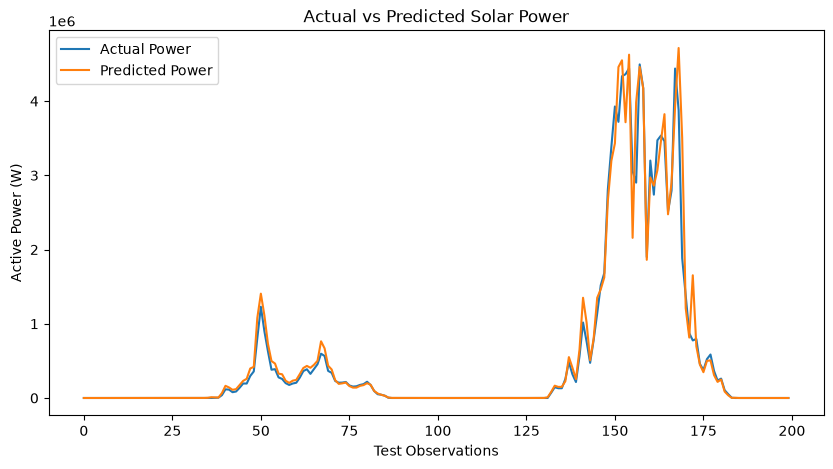

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(y_test.values[:200], label="Actual Power")
plt.plot(rf_predictions[:200], label="Predicted Power")

plt.xlabel("Test Observations")
plt.ylabel("Active Power (W)")
plt.title("Actual vs Predicted Solar Power")
plt.legend()
plt.show()

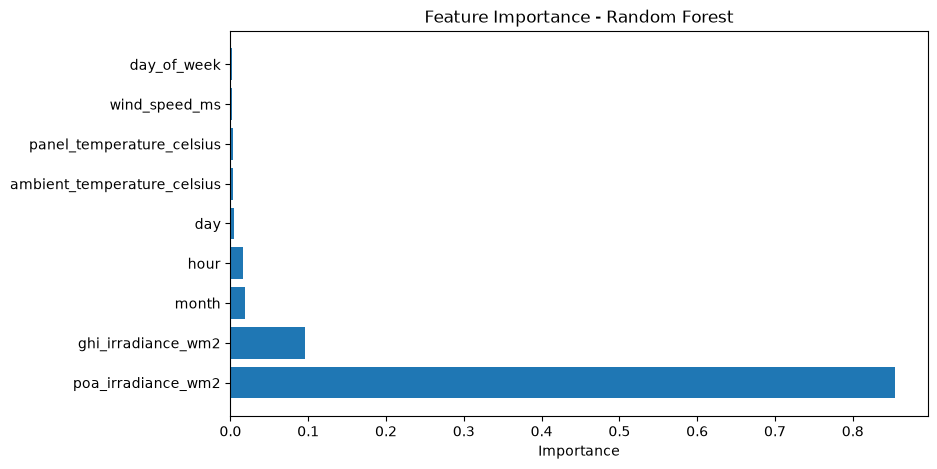

In [ ]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.title("Feature Importance - Random Forest")
#plt.gca().invert_yaxis()
plt.show()

In [22]:
importance

,Feature,Importance
1,poa_irradiance_wm2,0.853872
0,ghi_irradiance_wm2,0.096416
7,month,0.019334
5,hour,0.016111
6,day,0.003982
2,ambient_temperature_celsius,0.003298
3,panel_temperature_celsius,0.002996
4,wind_speed_ms,0.002534
8,day_of_week,0.001457


### Actual vs Predicted Power – Insights

- The predicted values closely follow the actual power values.
- The Random Forest model captures the major power-generation patterns.
- Some differences are visible during sudden increases and decreases in power.
- Overall, the model provides a good fit on the test observations.

### Feature Importance – Insights

- POA irradiance is the most important feature for predicting solar power generation.
- GHI irradiance is the second most important feature.
- Month and hour have smaller contributions.
- Temperature and wind speed have relatively low importance in this model.

### Conclusion

Random Forest performs well on the current test dataset. Irradiance features, particularly POA irradiance, play the most important role in its predictions.

### Compare Random Forest with and without flagged observations

In [24]:
df = df.sort_values("datetime").reset_index(drop=True)

split = int(len(df) * 0.8)

train = df.iloc[:split].copy()
test = df.iloc[split:].copy()

In [25]:
# Training with all observations
X_train = train[features]
y_train = train["total_active_power_w"]

# Training without flagged observations
clean_train = train[train["anomaly_flag"] == 0]

X_train_clean = clean_train[features]
y_train_clean = clean_train["total_active_power_w"]

# Same test data for both models
test = test[test["anomaly_flag"] == 0]

X_test = test[features]
y_test = test["total_active_power_w"]

In [26]:
# Model 1: With flagged observations
model1 = RandomForestRegressor(n_estimators=100, random_state=42)
model1.fit(X_train, y_train)

# Model 2: Without flagged observations
model2 = RandomForestRegressor(n_estimators=100, random_state=42)
model2.fit(X_train_clean, y_train_clean)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [27]:
pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)

In [28]:
comparison = pd.DataFrame({
    "Model": ["With Flagged Data", "Without Flagged Data"],
    "MAE": [
        mean_absolute_error(y_test, pred1),
        mean_absolute_error(y_test, pred2)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred1)),
        np.sqrt(mean_squared_error(y_test, pred2))
    ],
    "R2 Score": [
        r2_score(y_test, pred1),
        r2_score(y_test, pred2)
    ]
})

comparison

,Model,MAE,RMSE,R2 Score
0,With Flagged Data,178614.064860,368380.239662,0.958600
1,Without Flagged Data,177528.414055,365558.560869,0.959231


### Impact of Flagged Observations on Model Performance

Two Random Forest models were compared:

1. Model trained with all observations.
2. Model trained after excluding the two flagged observations.

The model without flagged observations performed slightly better.

- MAE decreased from 178,614 W to 177,528 W.
- RMSE decreased from 368,380 W to 365,559 W.
- R² increased from 0.9586 to 0.9592.

**Conclusion:** Removing the flagged observations resulted in a small improvement in model performance. Therefore, these observations may have some influence on prediction accuracy. However, the exact cause of the original data inconsistency remains unknown.

## Time-Series Cross-Validation

In [29]:
from sklearn.model_selection import TimeSeriesSplit

In [30]:
#Create five time-based splits
tscv = TimeSeriesSplit(n_splits=5)

for train_index, test_index in tscv.split(X):
    print("Training rows:", len(train_index))
    print("Testing rows:", len(test_index))

Training rows: 4011
Testing rows: 4010
Training rows: 8021
Testing rows: 4010
Training rows: 12031
Testing rows: 4010
Training rows: 16041
Testing rows: 4010
Training rows: 20051
Testing rows: 4010


### Evaluate Random Forest using cross-validation

In [31]:
mae_scores = []
rmse_scores = []
r2_scores = []

for train_index, test_index in tscv.split(X):

    X_train_cv = X.iloc[train_index]
    X_test_cv = X.iloc[test_index]

    y_train_cv = y.iloc[train_index]
    y_test_cv = y.iloc[test_index]

    model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_cv, y_train_cv)

    predictions = model.predict(X_test_cv)

    mae_scores.append(mean_absolute_error(y_test_cv, predictions))
    rmse_scores.append(np.sqrt(mean_squared_error(y_test_cv, predictions)))
    r2_scores.append(r2_score(y_test_cv, predictions))

In [32]:
cv_results = pd.DataFrame({
    "Split": [1, 2, 3, 4, 5],
    "MAE": mae_scores,
    "RMSE": rmse_scores,
    "R2 Score": r2_scores
})

cv_results

,Split,MAE,RMSE,R2 Score
0,1,241519.166530,465049.432333,0.913316
1,2,123359.777216,259597.793672,0.975966
2,3,115172.474956,284977.302760,0.977202
3,4,158715.765673,327210.665243,0.961632
4,5,171138.187224,363947.979259,0.960640


In [33]:
print("Average MAE:", np.mean(mae_scores))
print("Average RMSE:", np.mean(rmse_scores))
print("Average R2 Score:", np.mean(r2_scores))

Average MAE: 161981.07431978494
Average RMSE: 340156.63465356466
Average R2 Score: 0.9577511600367906


### Time-Series Cross-Validation

I used TimeSeriesSplit with five splits to evaluate the consistency of my Random Forest model across different time periods.

- The training dataset gradually increased in each split.
- Each testing set contained 4,010 observations.
- I evaluated the model using MAE, RMSE and R².
- The average R² score was approximately 0.9589.

This helped me evaluate model performance across multiple chronological periods rather than depending on a single train-test split.

### Hyperparameter tuning

In [34]:
from sklearn.model_selection import GridSearchCV

In [35]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, None],
    "min_samples_split": [2, 5]
}

In [36]:
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X, y)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, None], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_au

In [37]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV MAE: 161959.47597172816


In [38]:
tuning_results = pd.DataFrame(grid_search.cv_results_)

tuning_results = tuning_results[
    ["params", "mean_test_score", "rank_test_score"]
]

tuning_results["mean_test_MAE"] = -tuning_results["mean_test_score"]

tuning_results = tuning_results.drop(columns=["mean_test_score"])

tuning_results.sort_values("rank_test_score")

,params,rank_test_score,mean_test_MAE
5,"{'max_depth': None, 'min_samples_split': 2, 'n...",1,161959.475972
4,"{'max_depth': None, 'min_samples_split': 2, 'n...",2,161981.074320
3,"{'max_depth': 10, 'min_samples_split': 5, 'n_e...",3,162091.715081
6,"{'max_depth': None, 'min_samples_split': 5, 'n...",4,162428.624635
1,"{'max_depth': 10, 'min_samples_split': 2, 'n_e...",5,162478.675284
7,"{'max_depth': None, 'min_samples_split': 5, 'n...",6,162576.613752
2,"{'max_depth': 10, 'min_samples_split': 5, 'n_e...",7,162704.178054
0,"{'max_depth': 10, 'min_samples_split': 2, 'n_e...",8,162872.315287


In [39]:
best_model = grid_search.best_estimator_

best_model.fit(X, y)

print("Best model trained successfully!")

Best model trained successfully!


## correct data leakage

In [40]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

In [41]:
inverter = pd.read_csv(
    "../data/processed/PS_001_inverter_clean.csv",
    parse_dates=["datetime"]
)

weather = pd.read_csv(
    "../data/raw/BR-PVGen_meteorological/PS_001.csv",
    parse_dates=["datetime"]
)

In [42]:
weather = weather[
    [
        "datetime",
        "ps_id",
        "ghi_irradiance_wm2",
        "poa_irradiance_wm2",
        "ambient_temperature_celsius",
        "panel_temperature_celsius",
        "wind_speed_ms"
    ]
].copy()

weather.loc[weather["ghi_irradiance_wm2"] < 0, "ghi_irradiance_wm2"] = 0
weather.loc[weather["poa_irradiance_wm2"] < 0, "poa_irradiance_wm2"] = 0

In [45]:
plant_power = (
    inverter
    .groupby(["datetime", "ps_id"], as_index=False)
    .agg(
        total_active_power_w=(
            "total_active_power_w",
            lambda x: x.sum(min_count=1)
        )
    )
)

model_data = pd.merge(
    plant_power,
    weather,
    on=["datetime", "ps_id"],
    how="inner",
    validate="one_to_one"
)

model_data = model_data.dropna(
    subset=["total_active_power_w"]
).copy()

model_data = model_data.sort_values(
    "datetime"
).reset_index(drop=True)

model_data["hour"] = model_data["datetime"].dt.hour
model_data["day"] = model_data["datetime"].dt.day
model_data["month"] = model_data["datetime"].dt.month
model_data["day_of_week"] = model_data["datetime"].dt.dayofweek

print("Model data shape:", model_data.shape)

Model data shape: (24061, 12)


In [47]:
X = model_data[features]
y = model_data["total_active_power_w"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Missing feature values:", X.isnull().sum().sum())

Features shape: (24061, 9)
Target shape: (24061,)
Missing feature values: 2210


In [48]:
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(random_state=42, n_jobs=1))
])

The pipeline performs two operations:
1. SimpleImputer: fills missing weather values using training-data medians.
2. RandomForestRegressor: trains the prediction model.

In [49]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, None],
    "model__min_samples_split": [2, 5]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X, y)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [10, None], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.

In [50]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV MAE: 166565.29141359736


In [51]:
#Evaluate the corrected model on unseen data


split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

final_model = grid_search.best_estimator_

final_model.fit(X_train, y_train)

predictions = final_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))

MAE: 171979.9895914376
RMSE: 356201.9732243548
R2 Score: 0.9612916079526329


In [53]:
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])

lr_pipeline.fit(X_train, y_train)

lr_predictions = lr_pipeline.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, lr_predictions),
        mean_absolute_error(y_test, predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_predictions)),
        np.sqrt(mean_squared_error(y_test, predictions))
    ],
    "R2 Score": [
        r2_score(y_test, lr_predictions),
        r2_score(y_test, predictions)
    ]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,324925.934952,608363.228987,0.887088
1,Random Forest,171979.989591,356201.973224,0.961292


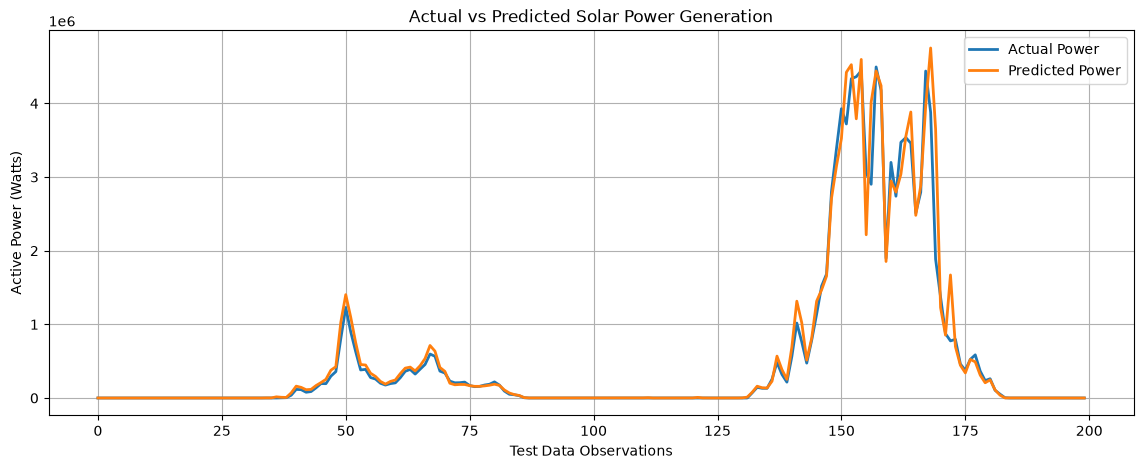

In [54]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.iloc[:200].values,
    label="Actual Power",
    linewidth=2
)

plt.plot(
    predictions[:200],
    label="Predicted Power",
    linewidth=2
)

plt.title("Actual vs Predicted Solar Power Generation")
plt.xlabel("Test Data Observations")
plt.ylabel("Active Power (Watts)")
plt.legend()
plt.grid(True)
plt.show()

Observations:
- Actual and predicted power values follow a very similar pattern.
- The model captures major increases and decreases in solar power generation.
- Predictions are particularly close during many stable generation periods.
- Some differences occur during sudden power fluctuations, especially around observations 150–170.  

Insight: Random Forest successfully captures the overall solar power generation pattern, but its predictions are less accurate during sudden changes in generation.

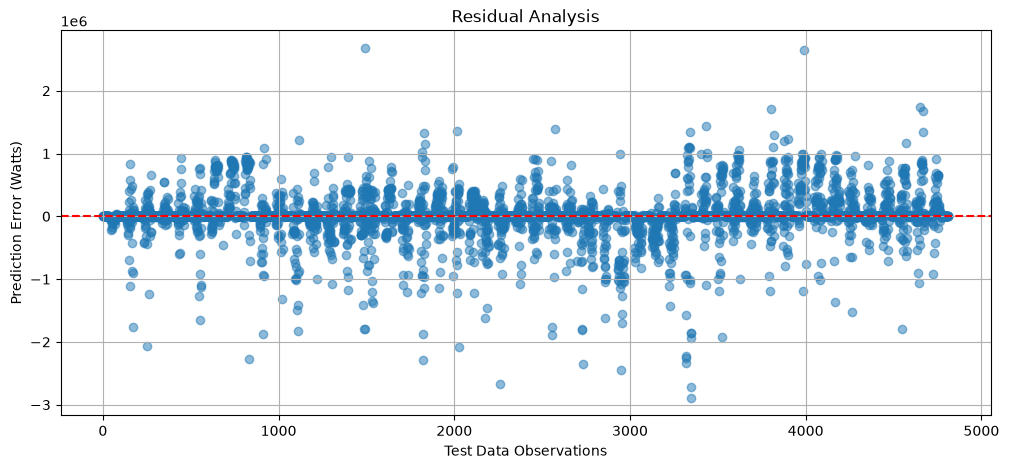

In [55]:
#Residual analysis
residuals = y_test.values - predictions

plt.figure(figsize=(12, 5))

plt.scatter(range(len(residuals)), residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Analysis")
plt.xlabel("Test Data Observations")
plt.ylabel("Prediction Error (Watts)")
plt.grid(True)
plt.show()

Observations from your graph:
- Most residuals are distributed around the zero reference line.
- Positive residuals indicate underprediction.
- Negative residuals indicate overprediction.
- A few large errors reach approximately +2.7 MW and -2.9 MW.
- Error spread varies across observations.

Insight: The model does not show a strong consistent overprediction or underprediction across the entire test set, but some observations have substantial prediction errors. The varying spread suggests prediction accuracy is not uniform.

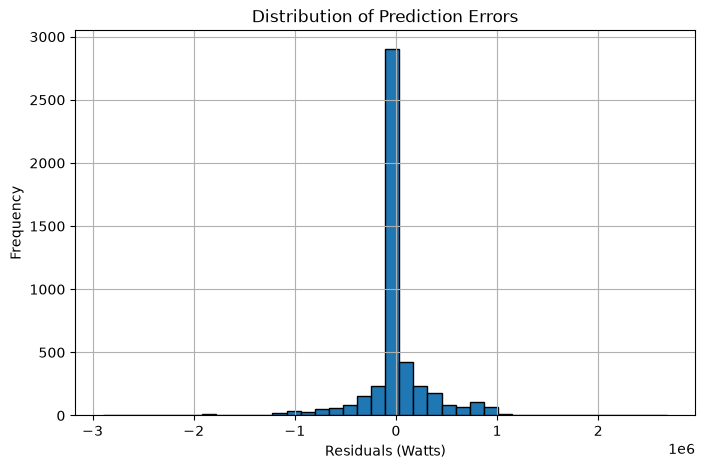

In [56]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=40, edgecolor="black")

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residuals (Watts)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

Observations from your graph:
- Most prediction errors are concentrated near zero.
- The histogram has a sharp peak around zero.
- The distribution has long tails on both sides.
- A few observations have very large positive and negative errors.

Insight: The model makes relatively small errors for many observations, but a small number of extreme errors affect overall prediction performance.

                       Feature  Importance
1           poa_irradiance_wm2    0.857636
0           ghi_irradiance_wm2    0.098097
7                        month    0.019098
5                         hour    0.015781
6                          day    0.002853
2  ambient_temperature_celsius    0.002220
3    panel_temperature_celsius    0.001953
4                wind_speed_ms    0.001470
8                  day_of_week    0.000893


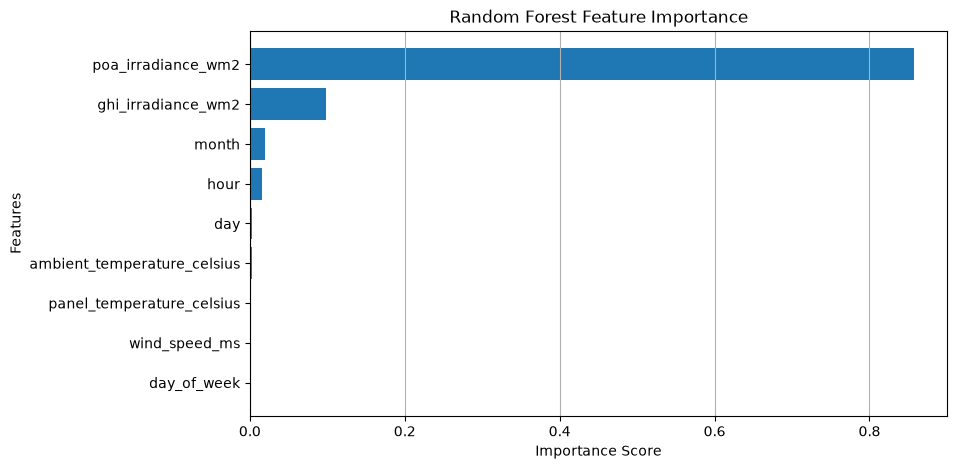

In [57]:
#Feature importance using the corrected model
importance = final_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.grid(axis="x")
plt.show()

In [58]:
!pip install joblib


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Aditi\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [59]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/random_forest_solar_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [60]:
#Test whether the saved model works
loaded_model = joblib.load(
    "../models/random_forest_solar_model.pkl"
)

test_predictions = loaded_model.predict(X_test.iloc[:5])

print("Sample predictions:", test_predictions)

Sample predictions: [14.65031777  0.0293849   0.0293849   0.0293849   0.0293849 ]


In [61]:
joblib.dump(
    features,
    "../models/feature_names.pkl"
)

print("Feature names saved successfully!")

Feature names saved successfully!
